# LeiData wav3 randomized dictionary

Summary of `learn_randomized_outer` on `SOCAL_H_76_230427_014845.x.wav` (30 GPL windows). The notebook loads the newest UTC-stamped directory under `wav3_randomized_latest` that contains `summary.json`.

This run used a coverage stop of 0.2, at most 5 outer passes, and templates at least 3 seconds wide (25 time bins; hop 24576 samples at 200 kHz). It stopped after one pass because time coverage was already above 0.2.

In [1]:
%matplotlib inline

from collections import Counter
from pathlib import Path
import json
import re

import matplotlib.pyplot as plt
import numpy as np
from IPython.display import Markdown, display

RESULT_BASE = Path(
    "/home/yfreund/whale_processing/result/LeiData/dict_learning_templates/wav3_randomized_latest"
)
RUN_STAMP_RE = re.compile(r"^\d{8}T\d{6}Z$")
START_FREQ_HZ = 10.0
END_FREQ_HZ = 10000.0
WINDOW_SEC = 75.0

stamped = sorted(
    p
    for p in RESULT_BASE.iterdir()
    if p.is_dir() and RUN_STAMP_RE.fullmatch(p.name) and (p / "summary.json").is_file()
)
if not stamped:
    raise FileNotFoundError(f"No summary.json under {RESULT_BASE}")

RESULT_DIR = stamped[-1]
summary = json.loads((RESULT_DIR / "summary.json").read_text())
matchings = json.loads((RESULT_DIR / "matchings.json").read_text())
outer_logs = [
    json.loads(line)
    for line in (RESULT_DIR / "outer_logs.jsonl").read_text().splitlines()
    if line.strip()
]
SEC_PER_BIN = float(summary["sec_per_bin"])

atoms = []
for atom in summary["atoms"]:
    data = np.load(RESULT_DIR / atom["path"])
    atoms.append({**atom, "data": np.asarray(data, dtype=np.float64)})
atoms.sort(key=lambda a: a["template_id"])

print(f"RESULT_DIR: {RESULT_DIR}")
print(f"atoms={len(atoms)} matchings={len(matchings)} outers={len(outer_logs)}")


RESULT_DIR: /home/yfreund/whale_processing/result/LeiData/dict_learning_templates/wav3_randomized_latest/20261021T220012Z
atoms=4 matchings=300 outers=1


## Run summary

In [2]:
energy_before = float(summary["energy_before"])
energy_after = float(summary["energy_after"])
explained = 1.0 - energy_after / energy_before
log = outer_logs[-1] if outer_logs else {}
n_bins_covered = log.get("n_bins_covered")
n_bins_total = log.get("n_bins_total")

rows = [
    ("Run", f"`{RESULT_DIR.name}`"),
    ("WAV", f"`{Path(summary['wav']).name}`"),
    ("Windows", str(summary["n_windows"])),
    ("GPL detections", str(summary["n_detections"])),
    ("Seed pool (width ≥ 3 s)", str(log.get("pool_size", "—"))),
    ("Seeds sampled", str(log.get("n_sampled", "—"))),
    ("Outer passes", f"{summary['n_outer_completed']} (cap {summary['max_outer']})"),
    ("Stop", f"`{summary['stop_reason']}` (threshold {summary['min_coverage']})"),
    ("Atoms", str(summary["n_atoms"])),
    ("Matchings", str(summary["n_matchings"])),
    (
        "Time coverage",
        f"{summary['time_coverage_fraction']:.1%} ({n_bins_covered}/{n_bins_total} bins)",
    ),
    ("Windows with a match", f"{summary['window_coverage_fraction']:.1%}"),
    ("Residual energy", f"{energy_before:.3e} → {energy_after:.3e}"),
    ("Energy explained", f"{explained:.1%}"),
    ("Min template length", f"{summary['min_template_width']} bins ({summary['min_template_width'] * SEC_PER_BIN:.2f} s)"),
    ("Distance gate", str(summary["post_refine_max_relative_distance"])),
    ("Min repeats", str(summary["n_min"])),
]

table = "\n".join(
    ["| | |", "|---|---|"] + [f"| {name} | {value} |" for name, value in rows]
)
display(Markdown(table))

atom_header = "| id | width (bins) | duration (s) | matchings | source detection |\n|---:|---:|---:|---:|---|"
atom_lines = []
for atom in atoms:
    atom_lines.append(
        f"| {atom['template_id']} | {atom['width']} | {atom['width'] * SEC_PER_BIN:.2f} | {atom['n_patches']} | `{atom['source_segment_id']}` |"
    )
display(Markdown("### Atoms\n\n" + atom_header + "\n" + "\n".join(atom_lines)))


| | |
|---|---|
| Run | `20261021T220012Z` |
| WAV | `SOCAL_H_76_230427_014845.x.wav` |
| Windows | 30 |
| GPL detections | 644 |
| Seed pool (width ≥ 3 s) | 80 |
| Seeds sampled | 5 |
| Outer passes | 1 (cap 5) |
| Stop | `coverage` (threshold 0.2) |
| Atoms | 4 |
| Matchings | 300 |
| Time coverage | 59.1% (10790/18270 bins) |
| Windows with a match | 100.0% |
| Residual energy | 2.057e+07 → 1.504e+07 |
| Energy explained | 26.9% |
| Min template length | 25 bins (3.07 s) |
| Distance gate | 0.9 |
| Min repeats | 10 |

### Atoms

| id | width (bins) | duration (s) | matchings | source detection |
|---:|---:|---:|---:|---|
| 0 | 45 | 5.53 | 66 | `spwhiten_SOCAL_H_76_230427_014845.x_w000020_s285000001_e300000000::det424::424` |
| 1 | 29 | 3.56 | 58 | `spwhiten_SOCAL_H_76_230427_014845.x_w000014_s195000001_e210000000::det307::307` |
| 2 | 27 | 3.32 | 113 | `spwhiten_SOCAL_H_76_230427_014845.x_w000009_s120000001_e135000000::det178::178` |
| 3 | 49 | 6.02 | 63 | `spwhiten_SOCAL_H_76_230427_014845.x_w000022_s315000001_e330000000::det458::458` |

## Templates

Shared color scale (5th–99.5th percentile, then cube root). Frequency is limited to 0–800 Hz, which contains every atom’s peak.

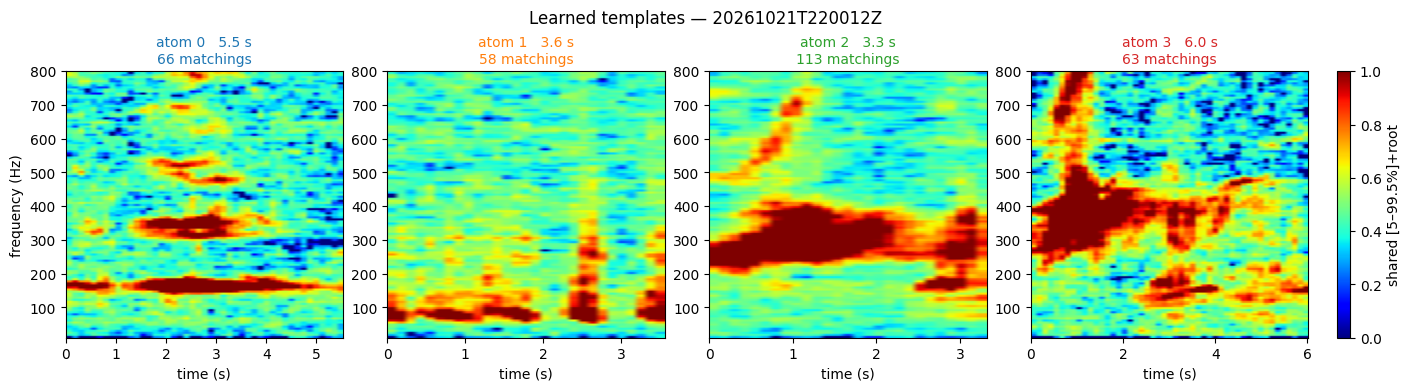

In [3]:
def percentile_scale(arr, lo=5.0, hi=99.5):
    p_lo, p_hi = np.percentile(np.asarray(arr), [lo, hi])
    return float(p_lo), float(p_hi)


def normalize_and_root(arr, lo, hi):
    scaled = np.clip((arr - lo) / (hi - lo + 1e-12), 0, 1)
    return np.cbrt(scaled)


def freq_hz(index, n_freq):
    return START_FREQ_HZ + index * (END_FREQ_HZ - START_FREQ_HZ) / n_freq


all_vals = np.concatenate([atom["data"].ravel() for atom in atoms])
lo, hi = percentile_scale(all_vals)
view_hi_hz = 800.0
colors = plt.cm.tab10(np.arange(10))

fig, axes = plt.subplots(
    1, len(atoms), figsize=(3.5 * len(atoms), 3.8), squeeze=False, layout="constrained"
)
im = None
for col, atom in enumerate(atoms):
    data = atom["data"]
    img = normalize_and_root(data, lo, hi)
    duration = data.shape[1] * SEC_PER_BIN
    ax = axes[0, col]
    im = ax.imshow(
        img,
        origin="lower",
        aspect="auto",
        cmap="jet",
        extent=[0, duration, START_FREQ_HZ, END_FREQ_HZ],
        vmin=0,
        vmax=1,
    )
    ax.set_ylim(START_FREQ_HZ, view_hi_hz)
    ax.set_title(
        f"atom {atom['template_id']}   {duration:.1f} s\n{atom['n_patches']} matchings",
        fontsize=10,
        color=colors[atom["template_id"] % 10],
    )
    ax.set_xlabel("time (s)")
    if col == 0:
        ax.set_ylabel("frequency (Hz)")

fig.colorbar(im, ax=axes[0].tolist(), fraction=0.046, pad=0.02, label="shared [5–99.5%]+root")
fig.suptitle(f"Learned templates — {RESULT_DIR.name}")
plt.show()


## Where the atoms were placed

Each row is one 75-second GPL window. A bar is one non-overlapping matching, drawn at its start time and template duration.

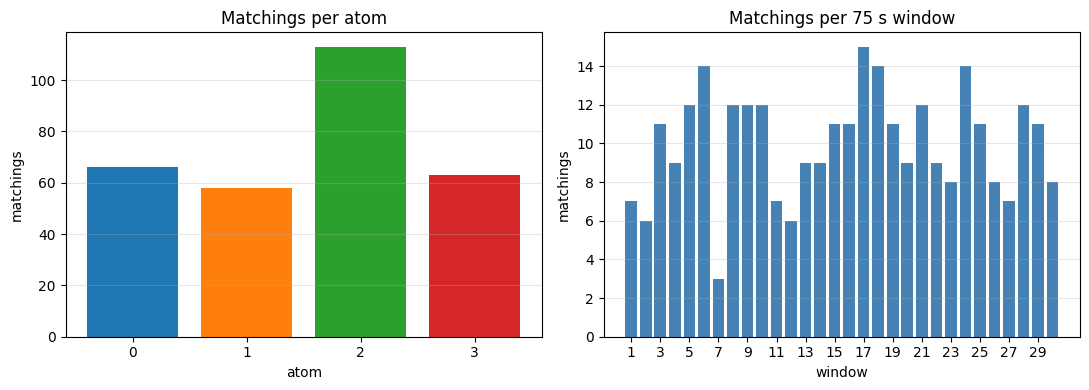

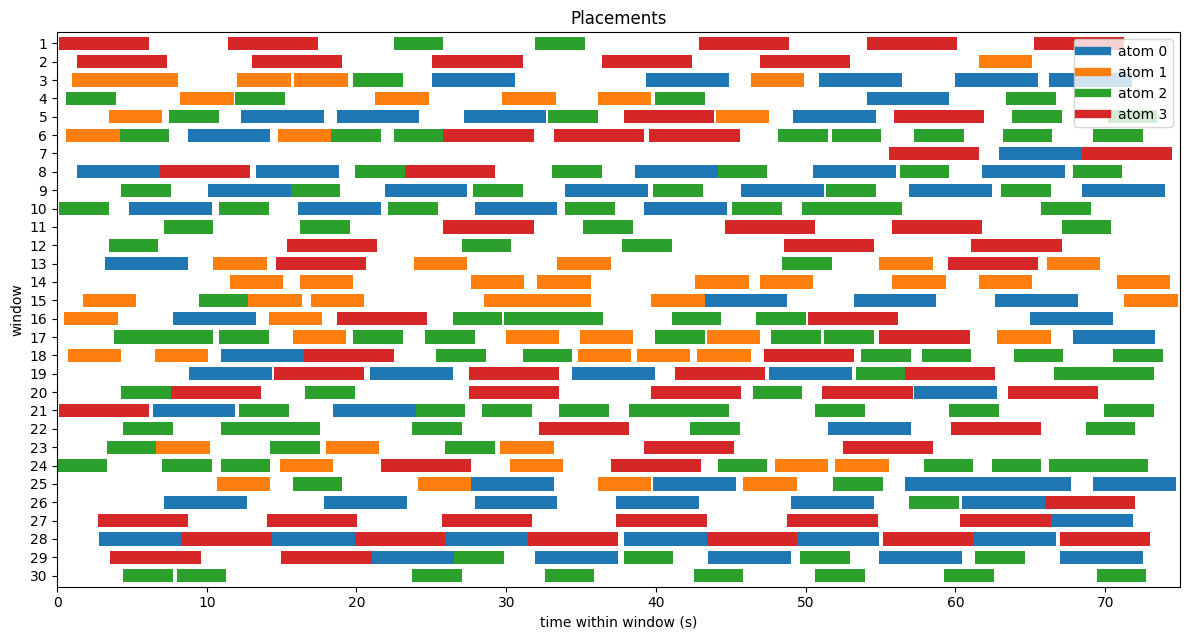

In [4]:
width_by_id = {atom["template_id"]: atom["width"] for atom in atoms}

def window_index(window_id: str) -> int:
    match = re.search(r"_w(\d+)_", window_id)
    if match is None:
        raise ValueError(f"no window index in {window_id}")
    return int(match.group(1))

counts = Counter(m["template_id"] for m in matchings)
per_window = Counter(window_index(m["window_id"]) for m in matchings)
window_ids = list(range(1, summary["n_windows"] + 1))

fig, axes = plt.subplots(1, 2, figsize=(11, 4))
ids = [atom["template_id"] for atom in atoms]
axes[0].bar(
    [str(i) for i in ids],
    [counts[i] for i in ids],
    color=[colors[i % 10] for i in ids],
)
axes[0].set_xlabel("atom")
axes[0].set_ylabel("matchings")
axes[0].set_title("Matchings per atom")
axes[0].grid(True, axis="y", alpha=0.3)

axes[1].bar(window_ids, [per_window[i] for i in window_ids], color="steelblue")
axes[1].set_xlabel("window")
axes[1].set_ylabel("matchings")
axes[1].set_title("Matchings per 75 s window")
axes[1].set_xticks(window_ids[::2])
axes[1].grid(True, axis="y", alpha=0.3)
fig.tight_layout()
plt.show()

fig, ax = plt.subplots(figsize=(12, 6.5))
for matching in matchings:
    tid = int(matching["template_id"])
    start = matching["t_start"] * SEC_PER_BIN
    duration = width_by_id[tid] * SEC_PER_BIN
    ax.barh(
        window_index(matching["window_id"]),
        duration,
        left=start,
        height=0.72,
        color=colors[tid % 10],
        align="center",
        linewidth=0,
    )
ax.set_yticks(window_ids)
ax.set_ylim(summary["n_windows"] + 0.6, 0.4)
ax.set_xlim(0, WINDOW_SEC)
ax.set_xlabel("time within window (s)")
ax.set_ylabel("window")
ax.set_title("Placements")
handles = [
    plt.Line2D([0], [0], color=colors[i % 10], lw=6, label=f"atom {i}")
    for i in ids
]
ax.legend(handles=handles, loc="upper right", frameon=True)
fig.tight_layout()
plt.show()
